# Analyse des performances du marketing digital

**Projet Data Analytics | Python • Pandas • Analyse marketing**

## Présentation

Analyse des données de marketing digital de Shapr, afin d'étudier les dépenses publicitaires et les performances des campagnes sur les réseaux sociaux.

## Objectifs

- Explorer et préparer les données des campagnes publicitaires.
- Analyser les dépenses marketing sur Facebook et Instagram.
- Étudier la répartition des investissements par canal.
- Comparer les dépenses publicitaires et identifier les tendances.

---

*Projet de portfolio réalisé à partir d'un challenge Data Analytics de Le Wagon.*

## **Load data**



Create a `data` folder in the same folder as this notebook.

Download [acquisition_facebook_adds.csv](https://drive.google.com/uc?export=download&id=1U4bXgai8KiEWLomvYqMAF-D-0zeKfU_l) and save it to your `data` folder.

<details>
<summary markdown="span">Not sure where your downloaded file went?</summary>

You can move it manually into the `data` folder, or run one of these in your terminal:

- **macOS/Linux:** `mv ~/Downloads/acquisition_facebook_adds.csv data/`
- **Windows (WSL):** `mv /mnt/c/Users/YOUR_USERNAME/Downloads/acquisition_facebook_adds.csv data/`

If you can't find your challenge folder, you can easily open it in Finder or File Explorer from your terminal:

- **macOS/Linux:** `open .`
- **Windows (WSL):** `explorer.exe .`

You can even do this from inside your notebook, but then you need to add an exclamation mark ('!') before your command: this allows you to run terminal commands from inside a notebook.

</details>

Load `acquisition_facebook_adds.csv` data in a DataFrame named `df_facebook`.


In [5]:
# YOUR CODE HERE
import pandas as pd
df_facebook = pd.read_csv("acquisition_facebook_adds.csv")

## **Data Discovery**


Display `df_facebook` DataFrame.


In [6]:
# YOUR CODE HERE
print(df_facebook)

             date   channel   spend
0      2019-08-01     Media   91.80
1      2019-08-01     Media   44.42
2      2019-08-01     Media   41.98
3      2019-08-01  Facebook    7.02
4      2019-08-01  Facebook    1.09
...           ...       ...     ...
73626  2019-01-18     Media   59.66
73627  2019-01-18     Media  126.23
73628  2019-01-18     Media   10.82
73629  2019-01-18     Media   13.90
73630  2019-01-18     Media  179.68

[73631 rows x 3 columns]


How many rows and columns are in this DataFrame ?


In [ ]:
# YOUR CODE HERE
df_facebook.shape

(73631, 3)

### **Columns selection**

Select only `date` and `spend` columns of this DataFrame and save the result in a `df_facebook_date_spend` variable.


In [15]:
# YOUR CODE HERE
df_facebook_date_spend = df_facebook [["date","spend"]]
df_facebook_date_spend

,date,spend
0,2019-08-01,91.80
1,2019-08-01,44.42
2,2019-08-01,41.98
3,2019-08-01,7.02
4,2019-08-01,1.09
...,...,...
73626,2019-01-18,59.66
73627,2019-01-18,126.23
73628,2019-01-18,10.82
73629,2019-01-18,13.90


### **Filtering**


f) Filter the `df_facebook` DataFrame only on the **Media** channel and save the result in a `df_facebook_media` variable.

In [32]:
# YOUR CODE HERE
x = (df_facebook["channel"] == "Media")
df_facebook_media = df_facebook[x]
df_facebook_media

,date,channel,spend
0,2019-08-01,Media,91.80
1,2019-08-01,Media,44.42
2,2019-08-01,Media,41.98
81,2019-08-01,Media,32.09
150,2019-08-01,Media,32.89
...,...,...,...
73626,2019-01-18,Media,59.66
73627,2019-01-18,Media,126.23
73628,2019-01-18,Media,10.82
73629,2019-01-18,Media,13.90


Filter the `df_facebook` DataFrame on the **Instagram** channel on January 13, 2019.


Save the result in a variable `df_facebook_instagram_20190113`, and export this DataFrame to the `data` folder as a csv file named `acquisition_facebook_instagram_20190113.csv`.

In [49]:
# YOUR CODE HERE
y = (df_facebook["channel"] == "Instagram") & (df_facebook["date"] == "2019-01-13")
df_facebook_instagram_20190113 = df_facebook[y]
df_facebook_instagram_20190113.to_csv("introduction_dataframe_data.csv", index=False)

In [ ]:
df_facebook_instagram_20190113.columns.tolist()

In [48]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'discovery',
    df_fb_shape=df_facebook.shape,
    df_fb_columns=df_facebook.columns.tolist(),
    df_fb_date_spend_shape=df_facebook_date_spend.shape,
    df_fb_date_spend_columns=df_facebook_date_spend.columns.tolist(),
    df_fb_media_shape=df_facebook_media.shape,
    df_fb_media_columns=df_facebook_media.columns.tolist(),
    df_fb_insta_20190113_shape=df_facebook_instagram_20190113.shape,
    df_fb_insta_20190113_columns=df_facebook_instagram_20190113.columns.tolist()
)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/kamguemalbert/.lewagon/venvs/lewagon/bin/python
cachedir: .pytest_cache
rootdir: /home/kamguemalbert/code/ALBERTKAMGUEM/06-Python/02-Intro-To-Python-Part2/data-analytics-digital-marketing-analysis/tests
plugins: anyio-4.8.0
collecting ... collected 9 items

test_discovery.py::TestDiscovery::test_df_date_spend_required_columns PASSED [ 11%]
test_discovery.py::TestDiscovery::test_df_date_spend_shape PASSED        [ 22%]
test_discovery.py::TestDiscovery::test_df_facebook_instagram_required_columns PASSED [ 33%]
test_discovery.py::TestDiscovery::test_df_facebook_instagram_shape PASSED [ 44%]
test_discovery.py::TestDiscovery::test_df_facebook_media_required_columns PASSED [ 55%]
test_discovery.py::TestDiscovery::test_df_facebook_media_shape PASSED    [ 66%]
test_discovery.py::TestDiscovery::test_df_facebook_not_empty PASSED      [ 77%]
test_d

## **Data Analysis**


### **Cast a date column to datetime**


In [50]:
# to check df actual dtypes
df_facebook.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73631 entries, 0 to 73630
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   date     73631 non-null  object 
 1   channel  73631 non-null  object 
 2   spend    73631 non-null  float64
dtypes: float64(1), object(2)
memory usage: 1.7+ MB


Convert the `date` column of the `df_facebook` DataFrame to datetime (a Python type for dates).

We'll use the `pd.to_datetime()` function to do this.

Have a look at the syntax in the course. Which **format** should you use here?

In [57]:
# YOUR CODE HERE
df_facebook["date"] = pd.to_datetime(df_facebook["date"])

In [58]:
# to check df format transformation
df_facebook.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73631 entries, 0 to 73630
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   date     73631 non-null  datetime64[ns]
 1   channel  73631 non-null  object        
 2   spend    73631 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 1.7+ MB


### **Aggregate functions**


Over what time period does the data extend?  
You can use the `.min()` and `.max()` aggregation functions on the `date` column.

In [62]:
# YOUR CODE HERE
x = df_facebook["date"].min()
y = df_facebook["date"].max()


Timestamp('2019-10-18 00:00:00')

Over the whole period, how much did Shapr spend?

In [68]:
# YOUR CODE HERE
z = df_facebook["spend"].sum()
z

1811170.169857

Calculate the amount of money spent by Shapr day by day.

To do this we will use the `.groupby()` function and then the `.sum()` aggregation function on the `spend` column.

We will store the result in a `df_facebook_daily` variable. You can refer to the lecture for syntax.


**Use the argument as_index=False to get a DataFrame as result**.

In [84]:
# YOUR CODE HERE
df_facebook_daily = df_facebook.groupby(["date"],as_index=False)[["spend"]].mean()
df_facebook_daily

,date,spend
0,2019-01-01,27.771020
1,2019-01-02,31.373775
2,2019-01-03,40.542778
3,2019-01-04,44.279545
4,2019-01-05,48.157640
...,...,...
286,2019-10-14,11.454167
287,2019-10-15,11.883750
288,2019-10-16,10.697586
289,2019-10-17,11.441923


We would like to extend the analysis by looking at the marketing spend strategy by channel over time.  


Calculate the amount spent per day per channel. We will store the result in a variable `df_facebook_channel_daily`.

**Use the argument as_index=False again to get a DataFrame as a result**

In [85]:
# YOUR CODE HERE
df_facebook_channel_daily = df_facebook.groupby(["date","channel"],as_index=False)["spend"].mean()
df_facebook_channel_daily

,date,channel,spend
0,2019-01-01,Facebook,28.248400
1,2019-01-01,Instagram,14.958936
2,2019-01-01,Media,70.356786
3,2019-01-02,Facebook,33.082692
4,2019-01-02,Instagram,17.322045
...,...,...,...
868,2019-10-17,Instagram,8.137222
869,2019-10-17,Media,48.170002
870,2019-10-18,Facebook,2.275714
871,2019-10-18,Instagram,1.603889


We want to display these values in a graph.

Execute the code below to achieve this (we will have a specific lecture on Data Viz with Python later in the bootcamp)

Comment on Shaphr investments.

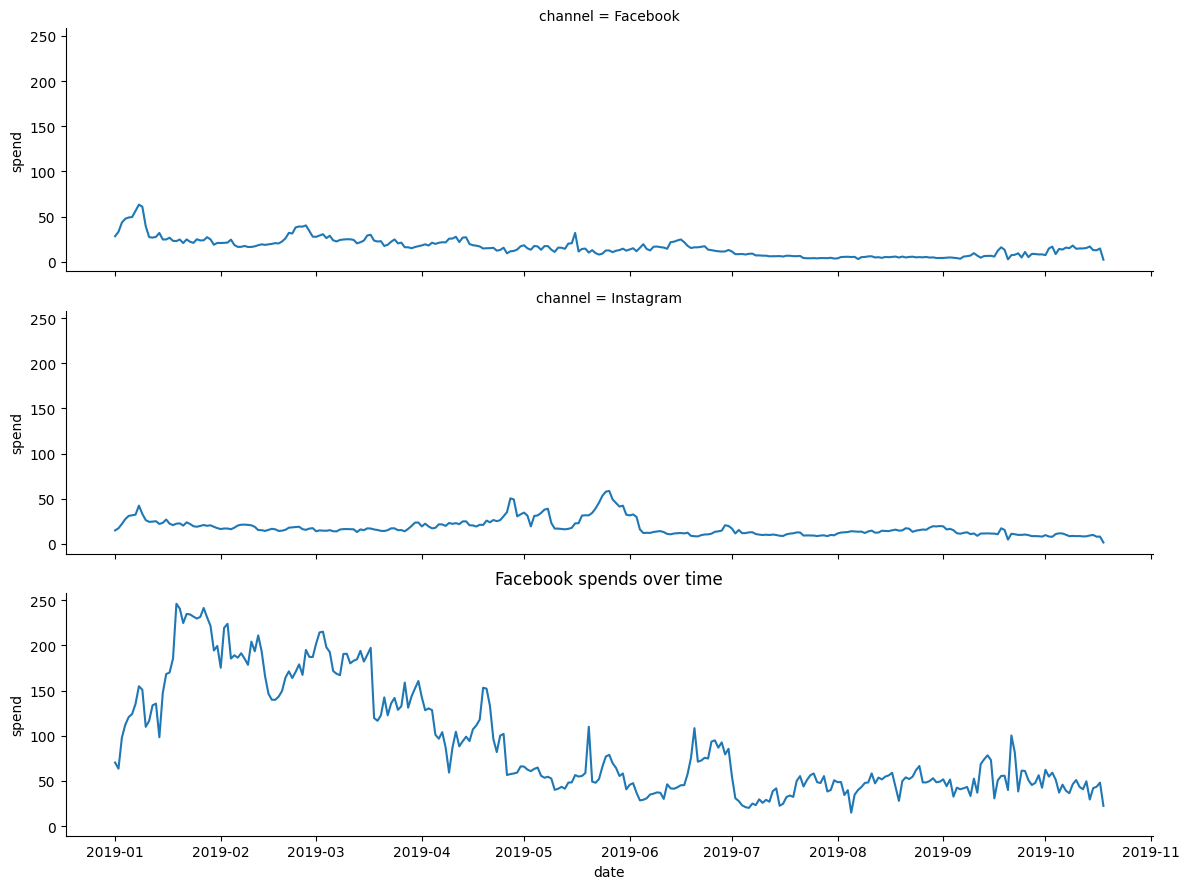

In [86]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.relplot(kind="line",
            data=df_facebook_channel_daily,
            x="date",
            y="spend",
            row="channel",
            height=3,
            aspect=12/3)
plt.xlabel("date")
plt.ylabel("spend")
plt.title("Facebook spends over time")
plt.show()

> **Your Answer Here (Double click)**



In [87]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'analysis',
    df_fb_shape=df_facebook.shape,
    df_fb_columns=df_facebook.columns.tolist(),
    df_fb_date=df_facebook['date'].dtype,
    df_fb_daily_shape=df_facebook_daily.shape,
    df_fb_daily_columns=df_facebook_daily.columns.tolist(),
    df_fb_channel_daily_shape=df_facebook_channel_daily.shape,
    df_fb_channel_daily_columns=df_facebook_channel_daily.columns.tolist(),
)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/kamguemalbert/.lewagon/venvs/lewagon/bin/python
cachedir: .pytest_cache
rootdir: /home/kamguemalbert/code/ALBERTKAMGUEM/06-Python/02-Intro-To-Python-Part2/data-analytics-digital-marketing-analysis/tests
plugins: anyio-4.8.0
collecting ... collected 8 items

test_analysis.py::TestAnalysis::test_df_date_spend_date_type PASSED      [ 12%]
test_analysis.py::TestAnalysis::test_df_facebook_channel_daily_required_columns PASSED [ 25%]
test_analysis.py::TestAnalysis::test_df_facebook_channel_daily_shape PASSED [ 37%]
test_analysis.py::TestAnalysis::test_df_facebook_daily_not_empty PASSED  [ 50%]
test_analysis.py::TestAnalysis::test_df_facebook_daily_required_columns PASSED [ 62%]
test_analysis.py::TestAnalysis::test_df_facebook_daily_shape PASSED      [ 75%]
test_analysis.py::TestAnalysis::test_df_facebook_required_columns PASSED [ 87%]
test_ana

## **Data Wrangling**


### **Join two dataframes**


Download [social_network_taxes.csv](https://drive.google.com/uc?export=download&id=1Lleeq3STLbX_wL6j6jNwlFt5eJRrIrAF) and save it to your `data` folder. Load it into a `df_taxes` DataFrame and display it.

<details>
<summary markdown="span">Not sure where your downloaded file went?</summary>

You can move it manually into the `data` folder, or run one of these in your terminal:

- **macOS/Linux:** `mv ~/Downloads/social_network_taxes.csv data/`
- **Windows (WSL):** `mv /mnt/c/Users/YOUR_USERNAME/Downloads/social_network_taxes.csv data/`

</details>

This table shows the **tax rate** applied by each social network (not real numbers). \
**I.e.** for a tax rate of 0.10 (meaning 10%), if you spend 100, the social network takes 10 as tax, leaving you with a real spend of 90.

In [89]:
# YOUR CODE HERE
import pandas as pd
df_taxes = pd.read_csv("social_network_taxes.csv")
print(df_taxes)

     channel   tax
0  Instagram  0.20
1   Facebook  0.15
2      Media  0.10


Merge the two DataFrames `df_facebook` and `df_taxes` and store the result in a variable `df_facebook_merged`.

Display `df_facebook_merged`, which new column has just appeared?

Look at the syntax in your course.

In [92]:
# YOUR CODE HERE
df_facebook_merged = pd.merge(df_facebook, df_taxes, on=["channel"], how="left")
df_facebook_merged

,date,channel,spend,tax
0,2019-08-01,Media,91.80,0.10
1,2019-08-01,Media,44.42,0.10
2,2019-08-01,Media,41.98,0.10
3,2019-08-01,Facebook,7.02,0.15
4,2019-08-01,Facebook,1.09,0.15
...,...,...,...,...
73626,2019-01-18,Media,59.66,0.10
73627,2019-01-18,Media,126.23,0.10
73628,2019-01-18,Media,10.82,0.10
73629,2019-01-18,Media,13.90,0.10


Create a new column in `df_facebook_merged` called `real_spend` that calculates the actual amount spent after deducting the tax.

Remember: the `tax` column contains a **tax rate** (e.g., 0.10 = 10%), not a flat fee amount.

To calculate the real spend, you need to:
1. Calculate the actual tax amount: `spend * tax`
2. Subtract it from the spend: `spend - (spend * tax)`

Or more simply: `spend * (1 - tax)`

<details>
    <summary markdown="span">**Hint** 💡</summary>

You can use the columns in a DataFrame as variables for doing arithmetic operations.

For example: `df["new_column"] = df["column_a"] * (1 - df["column_b"])`

</details>

In [95]:
# YOUR CODE HERE
df_facebook_merged["real_spend"] = df_facebook_merged["spend"] * (1 - df_facebook_merged["tax"])

In [96]:
from nbresult import ChallengeResult

result = ChallengeResult(
    'wrangling',
    df_fb_merged_shape=df_facebook_merged.shape,
    df_fb_merged_columns=df_facebook_merged.columns.tolist(),
    df_fb_merged_date=df_facebook_merged['date'].dtype,
    df_fb_merged_real_spend = df_facebook_merged['real_spend'].tolist(),
    df_real_spend_accuracy = (df_facebook_merged["spend"]*(1-df_facebook_merged["tax"])).tolist(),
    df_taxes_shape=df_taxes.shape,
    df_taxes_columns=df_taxes.columns.tolist()
)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-8.3.4, pluggy-1.5.0 -- /home/kamguemalbert/.lewagon/venvs/lewagon/bin/python
cachedir: .pytest_cache
rootdir: /home/kamguemalbert/code/ALBERTKAMGUEM/06-Python/02-Intro-To-Python-Part2/data-analytics-digital-marketing-analysis/tests
plugins: anyio-4.8.0
collecting ... collected 7 items

test_wrangling.py::TestWrangling::test_date_dtype PASSED                 [ 14%]
test_wrangling.py::TestWrangling::test_df_fb_merged_no_data_loss PASSED  [ 28%]
test_wrangling.py::TestWrangling::test_df_fb_merged_required_columns PASSED [ 42%]
test_wrangling.py::TestWrangling::test_df_fb_merged_shape PASSED         [ 57%]
test_wrangling.py::TestWrangling::test_df_taxes_required_columns PASSED  [ 71%]
test_wrangling.py::TestWrangling::test_df_taxes_shape PASSED             [ 85%]
test_wrangling.py::TestWrangling::test_real_spend_accuracy PASSED        [100%]

===========================